<a href="https://colab.research.google.com/github/drcrajc/all_cancer_ai/blob/main/extract_sample_cells.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Extract Sample ALL vs. HEM Cell Images (for Paper Introduction / Dataset Section)
Pulls a few representative images from each class in your flattened dataset and builds a clean,
labeled comparison figure — plus the individual images on their own, and a manifest recording
exactly which source files were used (useful if a reviewer ever asks which images appear in the
paper).

**Before running:** just needs Drive mounted — no GPU required, this is quick.

## 1. Mount Drive + config

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

# ---- CONFIG: adjust if your dataset location or desired sample count differs ----
FLAT_DIR = "/content/drive/MyDrive/leukemia_4model_run/data/flattened"  # must contain 'all/' and 'hem/' subfolders
N_PER_CLASS = 5    # how many sample images to show per class
SEED = 42           # fixed seed so re-running picks the same images

OUT_DIR = "/content/drive/MyDrive/leukemia_4model_run/sample_cell_figures"
os.makedirs(OUT_DIR, exist_ok=True)

assert os.path.isdir(FLAT_DIR), f"Flattened dataset not found at {FLAT_DIR} — check the path."
print("Using dataset:", FLAT_DIR)
print("Output folder:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using dataset: /content/drive/MyDrive/leukemia_4model_run/data/flattened
Output folder: /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures


## 2. Style + helper functions

In [ ]:
import random
import shutil
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt

# Shared publication style — matches the other figures already in the paper
PUB_STYLE = {
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
}
mpl.rcParams.update(PUB_STYLE)

CLASS_INFO = [
    ("all", "ALL (Leukemic Blast Cells)"),
    ("hem", "HEM (Normal / Healthy Cells)"),
]


def select_samples(flat_dir, n_per_class, seed):
    """Randomly (but reproducibly) picks n_per_class file paths from each class folder."""
    random.seed(seed)
    selected = {}
    for class_folder, _ in CLASS_INFO:
        class_dir = Path(flat_dir) / class_folder
        if not class_dir.is_dir():
            raise FileNotFoundError(
                f"Expected class folder not found: {class_dir}\n"
                f"Check that FLAT_DIR points at the folder containing 'all/' and 'hem/' subfolders."
            )
        files = [p for p in class_dir.iterdir() if p.is_file()]
        if len(files) < n_per_class:
            raise ValueError(
                f"Class '{class_folder}' only has {len(files)} images, "
                f"but {n_per_class} were requested."
            )
        selected[class_folder] = random.sample(files, n_per_class)
    return selected


def save_individual_crops(selected, out_dir):
    """Copies each selected image out individually, renamed for easy reference in the paper."""
    saved_paths = {}
    for class_folder, _ in CLASS_INFO:
        saved_paths[class_folder] = []
        for i, src_path in enumerate(selected[class_folder], start=1):
            ext = src_path.suffix
            dest_name = f"{class_folder}_sample_{i}{ext}"
            dest_path = Path(out_dir) / dest_name
            shutil.copy(src_path, dest_path)
            saved_paths[class_folder].append(dest_path)
    return saved_paths


def build_comparison_grid(selected, out_dir, n_per_class):
    """Builds the labeled 2-row (ALL / HEM) x n_per_class comparison grid figure."""
    fig, axes = plt.subplots(2, n_per_class, figsize=(2.6 * n_per_class, 6))
    if n_per_class == 1:
        axes = axes.reshape(2, 1)

    for row, (class_folder, class_title) in enumerate(CLASS_INFO):
        for col in range(n_per_class):
            ax = axes[row, col]
            img_path = selected[class_folder][col]
            img = plt.imread(img_path)
            ax.imshow(img)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_linewidth(1.2)
            ax.set_xlabel(f"Sample {col + 1}", fontsize=9)
        axes[row, 0].set_ylabel(class_title, fontsize=10, fontweight="bold")

    fig.suptitle("Representative Cell Morphology Variants: ALL vs. HEM",
                 fontsize=13, fontweight="bold", y=1.02)
    fig.tight_layout()
    out_path = os.path.join(out_dir, "fig_sample_all_vs_hem_grid.png")
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    return out_path


def write_manifest(selected, out_dir):
    """Records exactly which source files were used, for reproducibility / paper appendix."""
    manifest_path = os.path.join(out_dir, "selected_filenames.txt")
    with open(manifest_path, "w") as f:
        for class_folder, class_title in CLASS_INFO:
            f.write(f"{class_title}:\n")
            for p in selected[class_folder]:
                f.write(f"  {p}\n")
            f.write("\n")
    return manifest_path

## 3. Select images, build the figure, save everything

Selecting 5 images per class from /content/drive/MyDrive/leukemia_4model_run/data/flattened (seed=42) ...
Saving individual crops ...
  Saved /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures/all_sample_1.bmp
  Saved /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures/all_sample_2.bmp
  Saved /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures/all_sample_3.bmp
  Saved /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures/all_sample_4.bmp
  Saved /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures/all_sample_5.bmp
  Saved /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures/hem_sample_1.bmp
  Saved /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures/hem_sample_2.bmp
  Saved /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures/hem_sample_3.bmp
  Saved /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures/hem_sample_4.bmp
  Saved /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures/hem

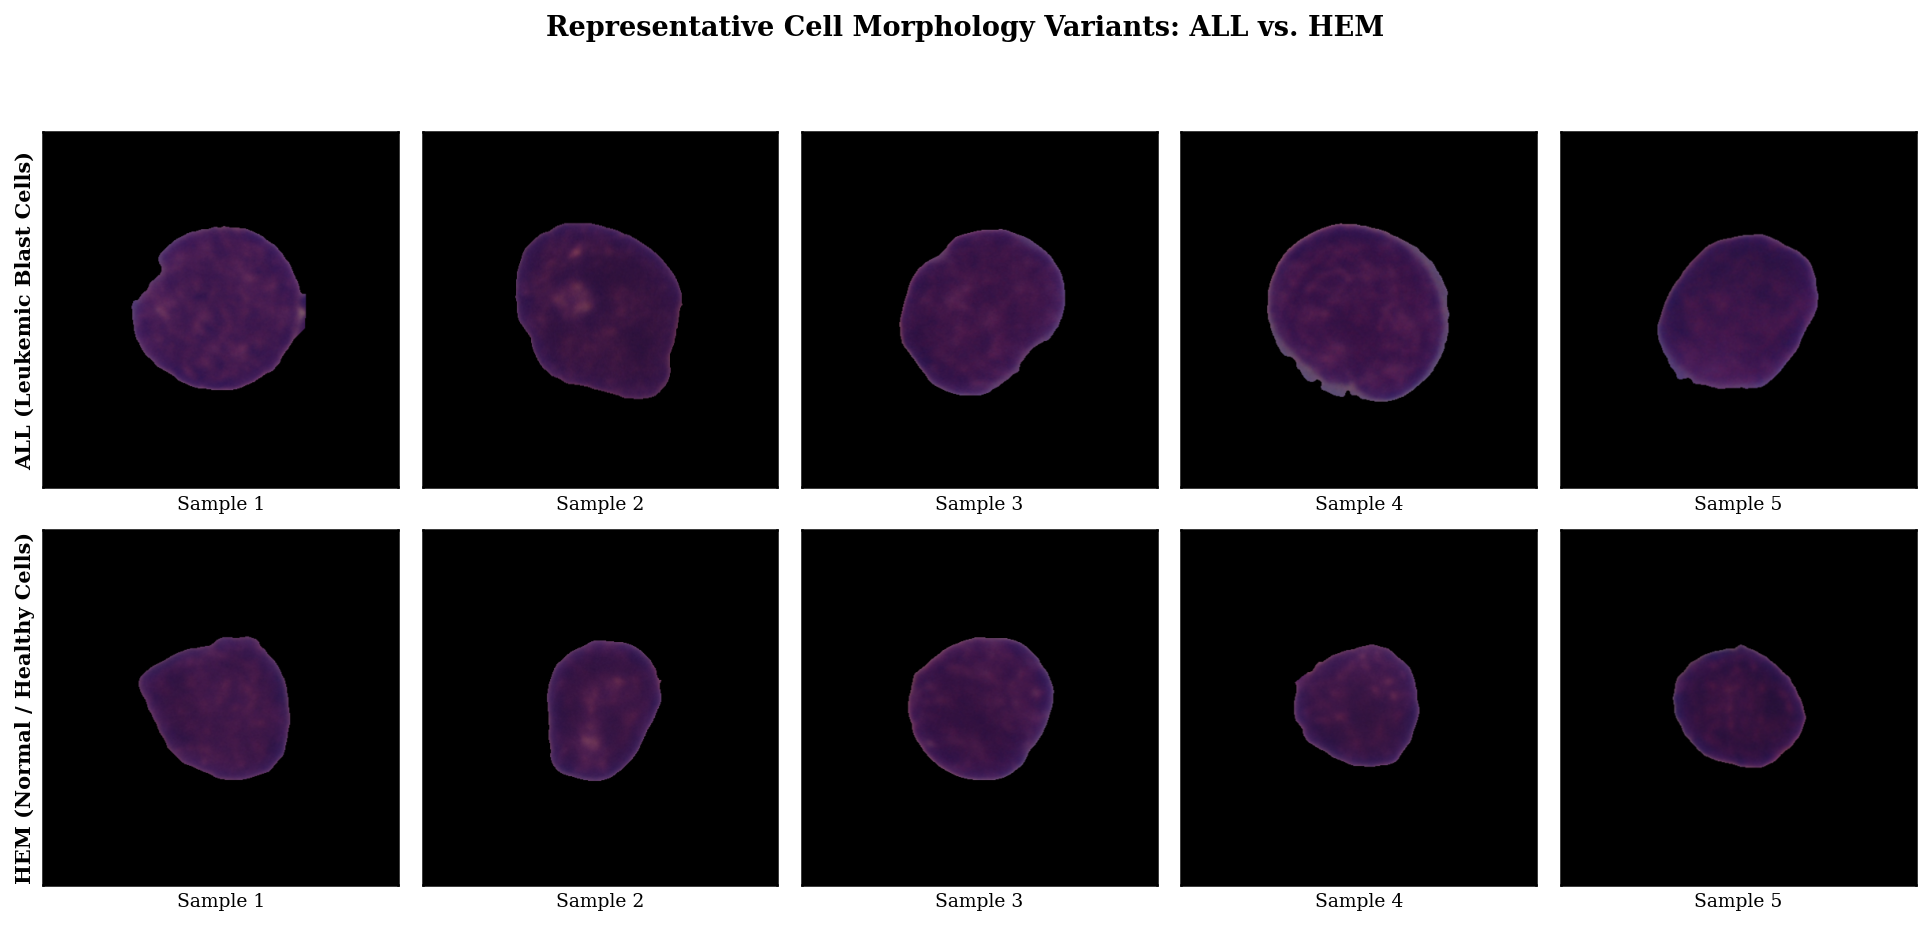

  Saved /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures/fig_sample_all_vs_hem_grid.png
Wrote manifest of selected source filenames to /content/drive/MyDrive/leukemia_4model_run/sample_cell_figures/selected_filenames.txt


In [ ]:
print(f"Selecting {N_PER_CLASS} images per class from {FLAT_DIR} (seed={SEED}) ...")
selected = select_samples(FLAT_DIR, N_PER_CLASS, SEED)

print("Saving individual crops ...")
saved_paths = save_individual_crops(selected, OUT_DIR)
for class_folder, paths in saved_paths.items():
    for p in paths:
        print(f"  Saved {p}")

print("Building comparison grid figure ...")
grid_path = build_comparison_grid(selected, OUT_DIR, N_PER_CLASS)
print(f"  Saved {grid_path}")

manifest_path = write_manifest(selected, OUT_DIR)
print(f"Wrote manifest of selected source filenames to {manifest_path}")

## 4. Zip and download

In [ ]:
import shutil as sh

sh.make_archive("/content/sample_cell_figures", "zip", OUT_DIR)
from google.colab import files as colab_files
colab_files.download("/content/sample_cell_figures.zip")

print("\nDone. Copy fig_sample_all_vs_hem_grid.png into your paper's figures/ folder and")
print("uncomment the corresponding \\includegraphics line in the .tex file.")
print("\nIf you'd rather try a different random set of images, just change SEED in cell 1 and re-run.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Done. Copy fig_sample_all_vs_hem_grid.png into your paper's figures/ folder and
uncomment the corresponding \includegraphics line in the .tex file.

If you'd rather try a different random set of images, just change SEED in cell 1 and re-run.
